# Model training and experiment tracking

This notebook trains and evaluates heart-disease classifiers, tracks the experiments, and saves a reusable prediction pipeline. It covers the assignment's model-development and experiment-tracking tasks: two classifiers, preprocessing, stratified evaluation with cross-validation, relevant classification metrics, and MLflow logging of parameters, metrics, model artifacts, and ROC plots.

**Workflow:** load the cleaned dataset → separate predictors and target → create a stratified 80/20 train/test split → compare Logistic Regression and Random Forest using five-fold cross-validation and held-out metrics → select a model → refit the selected pipeline on all available data and save it for inference.

The UCI dataset's categorical fields are already represented by numeric codes. This workflow imputes missing predictor values with the median and scales features inside a scikit-learn pipeline; it does not add one-hot encoding. Run the data-preparation notebook first if `data/processed/heart_clean.csv` is missing. Outputs are saved under `artifacts/`, `models/`, and the local MLflow store `mlruns/`.

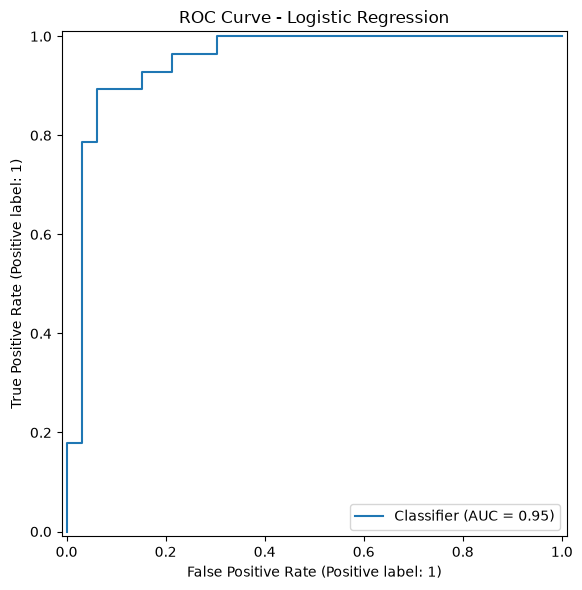

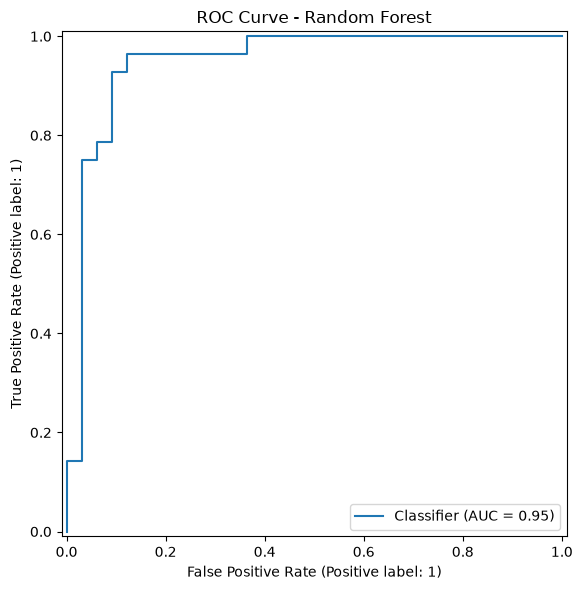

,run_id,cv_roc_auc_mean,cv_roc_auc_std,accuracy,precision,recall,roc_auc
name,,,,,,,
logistic_regression,7fc372f8ac644975b29f0859d335d786,0.896,0.015,0.869,0.812,0.929,0.951
random_forest,690258246a0643189d392ee2b1966c59,0.882,0.028,0.902,0.867,0.929,0.949


In [1]:
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Step 1: Locate the project root and verify the cleaned dataset exists.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "train.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing train.py.")
data_path = project_root / "data" / "processed" / "heart_clean.csv"
if not data_path.is_file():
    raise FileNotFoundError("Run 01_data_acquisition_and_cleaning.ipynb or python download.py first.")

# Step 2: Configure local MLflow file-store tracking and load predictors/target.
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
mlflow.set_tracking_uri((project_root / "mlruns").as_uri())
mlflow.set_experiment("heart_disease_classification")
df = pd.read_csv(data_path)
if "target" not in df.columns:
    raise ValueError("The cleaned dataset must contain a target column.")
X = df.drop(columns=["target"])
y = df["target"]

# Step 3: Create a stratified 80/20 train/test split and 5-fold CV splitter.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

candidate_models = {
    "logistic_regression": LogisticRegression(max_iter=2000, random_state=42),
    "random_forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, random_state=42
    ),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
artifact_dir = project_root / "artifacts"
artifact_dir.mkdir(exist_ok=True)
results = []

# Step 4: Evaluate each candidate pipeline with 5-fold CV, test split, and MLflow logging.
for name, estimator in candidate_models.items():
    pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", estimator),
        ]
    )
    cv_auc = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="roc_auc"
    )
    pipeline.fit(X_train, y_train)
    y_probability = pipeline.predict_proba(X_test)[:, 1]
    y_prediction = pipeline.predict(X_test)
    metrics = {
        "cv_roc_auc_mean": float(cv_auc.mean()),
        "cv_roc_auc_std": float(cv_auc.std()),
        "accuracy": float(accuracy_score(y_test, y_prediction)),
        "precision": float(precision_score(y_test, y_prediction, zero_division=0)),
        "recall": float(recall_score(y_test, y_prediction, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, y_probability)),
    }
    artifact_path = artifact_dir / f"{name}_pipeline.joblib"
    joblib.dump(pipeline, artifact_path)

    with mlflow.start_run(run_name=name) as run:
        mlflow.log_param("model_name", name)
        mlflow.log_params(estimator.get_params())
        mlflow.log_metrics(metrics)
        mlflow.log_artifact(str(artifact_path), artifact_path="model_artifact")
        figure, axis = plt.subplots(figsize=(7, 6))
        RocCurveDisplay.from_predictions(y_test, y_probability, ax=axis)
        axis.set_title(f"ROC Curve - {name.replace('_', ' ').title()}")
        figure.tight_layout()
        roc_path = artifact_dir / f"{name}_roc_curve.png"
        figure.savefig(roc_path, dpi=200, bbox_inches="tight")
        mlflow.log_artifact(str(roc_path), artifact_path="plots")
        plt.show()
        plt.close(figure)

    results.append(
        {"name": name, "run_id": run.info.run_id, **metrics, "pipeline": pipeline}
    )

results_table = pd.DataFrame(
    [{key: value for key, value in result.items() if key != "pipeline"} for result in results]
).set_index("name")
display(results_table.round(3))

## How to read the comparison

- `cv_roc_auc_mean` and `cv_roc_auc_std` summarize ROC-AUC across five stratified folds of the training split. A higher mean and lower variation indicate stronger, more consistent ranking performance (`0.896 ± 0.015` for Logistic Regression vs. `0.882 ± 0.028` for Random Forest).
- `accuracy` is the proportion of correct test predictions; `precision` is the proportion of predicted disease cases that are truly positive; `recall` is the proportion of actual disease cases detected; and `roc_auc` summarizes ranking performance across classification thresholds.
- **Model configuration and tuning rationale:** Logistic Regression is configured with `max_iter=2000` and L2 regularization (`C=1.0`) to guarantee solver convergence on standardized clinical predictors. Random Forest is configured with `n_estimators=200` and `min_samples_leaf=2` to reduce variance and prevent single-sample leaf overfitting on this 303-patient dataset.
- Each MLflow run logs the model name, estimator hyperparameters, cross-validation and held-out test metrics, the fitted scikit-learn pipeline (`model_artifact/`), and its ROC curve plot (`plots/`). Copies are also saved locally under `artifacts/`.
- To inspect the logged runs interactively, open a PowerShell terminal at the project root and run:
  ```powershell
  $env:MLFLOW_ALLOW_FILE_STORE = "true"
  mlflow ui --backend-store-uri .\mlruns --host 127.0.0.1 --port 5000
  ```

## Select and save the final pipeline

For consistency with `train.py`, the highest held-out ROC-AUC selects the model in this assignment demonstration. The selected pipeline is then refit on all rows and saved as `models/heart_disease_pipeline.joblib`; `models/training_summary.json` records the selected model and its held-out metrics. Because the same test results are used both to choose and report the winner, those metrics may be optimistic. For an unbiased final estimate, select using cross-validation or a separate validation set, then evaluate the selected model on a test set only once.

In [2]:
best_result = max(results, key=lambda result: result["roc_auc"])
final_pipeline = best_result["pipeline"]
final_pipeline.fit(X, y)

model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "heart_disease_pipeline.joblib"
joblib.dump(final_pipeline, model_path)
summary = {
    "best_model": best_result["name"],
    "model_path": str(model_path),
    "metrics": {
        key: best_result[key]
        for key in ("roc_auc", "accuracy", "precision", "recall")
    },
}
summary_path = model_dir / "training_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))
print(f"MLflow tracking data: {project_root / 'mlruns'}")

{
  "best_model": "logistic_regression",
  "model_path": "d:\\03_Semester\\Semester03\\MLOps\\Assignment\\heart-disease-mlops\\models\\heart_disease_pipeline.joblib",
  "metrics": {
    "roc_auc": 0.9512987012987013,
    "accuracy": 0.8688524590163934,
    "precision": 0.8125,
    "recall": 0.9285714285714286
  }
}
MLflow tracking data: d:\03_Semester\Semester03\MLOps\Assignment\heart-disease-mlops\mlruns
